<a href="https://colab.research.google.com/github/Diyah-futadya/UTS-PENAMBANGAN-DATA/blob/main/Klasifikasi_Stunting_Posyandu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
upload = files.upload()

print("Dataset berhasil diunggah!")

Saving data_balita.csv to data_balita.csv
Dataset berhasil diunggah!


In [4]:
file_name = list(upload.keys())[0]

df = pd.read_csv(file_name)

print("Lima data pertama:")
display(df.head())

Lima data pertama:


,Umur (bulan),Jenis Kelamin,Tinggi Badan (cm),Status Gizi
0,0,laki-laki,44.591973,stunted
1,0,laki-laki,56.705203,tinggi
2,0,laki-laki,46.863358,normal
3,0,laki-laki,47.508026,normal
4,0,laki-laki,42.743494,severely stunted


In [6]:
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

print("\nNama kolom:")
print(df.columns.tolist())

print("\nInformasi dataset:")
df.info()

display(df.describe(include='all'))

Jumlah baris: 120999
Jumlah kolom: 4

Nama kolom:
['Umur (bulan)', 'Jenis Kelamin', 'Tinggi Badan (cm)', 'Status Gizi']

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120999 entries, 0 to 120998
Data columns (total 4 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Umur (bulan)       120999 non-null  int64  
 1   Jenis Kelamin      120999 non-null  object 
 2   Tinggi Badan (cm)  120999 non-null  float64
 3   Status Gizi        120999 non-null  object 
dtypes: float64(1), int64(1), object(2)
memory usage: 3.7+ MB


,Umur (bulan),Jenis Kelamin,Tinggi Badan (cm),Status Gizi
count,120999.000000,120999,120999.000000,120999
unique,NaN,2,NaN,4
top,NaN,perempuan,NaN,normal
freq,NaN,61002,NaN,67755
mean,30.173803,NaN,88.655434,NaN
std,17.575119,NaN,17.300997,NaN
min,0.000000,NaN,40.010437,NaN
25%,15.000000,NaN,77.000000,NaN
50%,30.000000,NaN,89.800000,NaN
75%,45.000000,NaN,101.200000,NaN


In [7]:
print("Jumlah missing values:")
print(df.isnull().sum())

print("\nPresentase missing values:")
print((df.isnull().mean()*100).round(2))

Jumlah missing values:
Umur (bulan)         0
Jenis Kelamin        0
Tinggi Badan (cm)    0
Status Gizi          0
dtype: int64

Presentase missing values:
Umur (bulan)         0.0
Jenis Kelamin        0.0
Tinggi Badan (cm)    0.0
Status Gizi          0.0
dtype: float64


In [8]:
jumlah_duplikat = df.duplicated().sum()

print("Jumlah data duplikat:", jumlah_duplikat)

df = df.drop_duplicates()

print("Jumlah data setelah menghapus duplikat:", len(df))

Jumlah data duplikat: 81574
Jumlah data setelah menghapus duplikat: 39425


In [9]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_', regex=False)
)

print("Nama kolom setelah dibersihkan:")
print(df.columns.tolist())

Nama kolom setelah dibersihkan:
['umur_(bulan)', 'jenis_kelamin', 'tinggi_badan_(cm)', 'status_gizi']


In [10]:
print(df.columns.tolist())

pemetaan = {}

for kolom in df.columns:
    nama = kolom.lower()

    if 'umur' in nama or 'age' in nama:
        pemetaan[kolom] = 'umur'

    elif 'gender' in nama or 'kelamin' in nama or 'sex' in nama:
         pemetaan[kolom] = 'jenis_kelamin'

    elif 'height' in nama or 'tinggi' in nama:
          pemetaan[kolom] = 'tinggi_badan'

    elif 'status' in nama:
          pemetaan[kolom] = 'status'

df = df.rename(columns=pemetaan)

kolom_pilihan = [
    'umur',
    'jenis_kelamin',
    'tinggi_badan',
    'status'
]

data = df[kolom_pilihan].copy()

display(data.head())



['umur_(bulan)', 'jenis_kelamin', 'tinggi_badan_(cm)', 'status_gizi']


,umur,jenis_kelamin,tinggi_badan,status
0,0,laki-laki,44.591973,stunted
1,0,laki-laki,56.705203,tinggi
2,0,laki-laki,46.863358,normal
3,0,laki-laki,47.508026,normal
4,0,laki-laki,42.743494,severely stunted


In [12]:
data['umur'] = pd.to_numeric(
    data['umur'], errors='coerce'
)

data['tinggi_badan'] = pd.to_numeric(
    data['tinggi_badan'], errors='coerce'
)

data['jenis_kelamin'] = (
    data['jenis_kelamin']
    .astype('string')
    .str.strip()
    .str.lower()
)

data['status'] = (
    data['status']
    .astype('string')
    .str.strip()
    .str.lower()
)

display(data.head())
data.info()

,umur,jenis_kelamin,tinggi_badan,status
0,0,laki-laki,44.591973,stunted
1,0,laki-laki,56.705203,tinggi
2,0,laki-laki,46.863358,normal
3,0,laki-laki,47.508026,normal
4,0,laki-laki,42.743494,severely stunted


<class 'pandas.core.frame.DataFrame'>
Index: 39425 entries, 0 to 120993
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   umur           39425 non-null  int64  
 1   jenis_kelamin  39425 non-null  string 
 2   tinggi_badan   39425 non-null  float64
 3   status         39425 non-null  string 
dtypes: float64(1), int64(1), string(2)
memory usage: 1.5 MB


In [19]:
print(data.isnull().sum())

data = data.dropna(
    subset=[
        'umur',
        'jenis_kelamin',
        'tinggi_badan',
        'status'
    ]
)

print("Jumlah data setelah pembersihan:", data.shape)


umur             0
jenis_kelamin    0
tinggi_badan     0
status           0
dtype: int64
Jumlah data setelah pembersihan: (39425, 4)


In [20]:
print("umur terkecil:", data['umur'].min())
print("umur terbesar:", data['umur'].max())

print("tinggi terkecil:", data['tinggi_badan'].min())
print("tinggi terbesar:", data['tinggi_badan'].max())

data =data[
    (data['umur'] >= 0) &
    (data['tinggi_badan'] > 0)
].copy()

print("Data setelah pemeriksaan:", data.shape)

umur terkecil: 0
umur terbesar: 60
tinggi terkecil: 40.0104370037594
tinggi terbesar: 128.0
Data setelah pemeriksaan: (39425, 4)


In [22]:
print(data['jenis_kelamin'].value_counts())

data['jenis_kelamin'] = data['jenis_kelamin'].astype(object).replace({
    'laki-laki': 1,
    'perempuan': 0,
    'male': 1,
    'female': 0
}).astype(int)

print(data['jenis_kelamin'].value_counts())

jenis_kelamin
perempuan    20024
laki-laki    19401
Name: count, dtype: Int64
jenis_kelamin
0    20024
1    19401
Name: count, dtype: int64


/tmp/ipykernel_2307/2571187298.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['jenis_kelamin'] = data['jenis_kelamin'].astype(object).replace({


status
normal              21514
tinggi               6974
severely stunted     6520
stunted              4417
Name: count, dtype: Int64


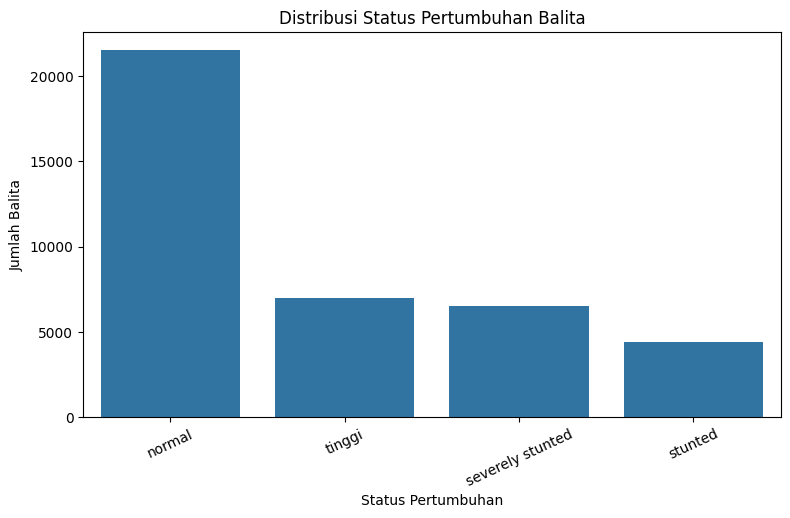

In [23]:
print(data['status'].value_counts())

plt.figure(figsize=(9, 5))

sns.countplot(
    data=data,
    x='status',
    order=data['status'].value_counts().index
)

plt.title('Distribusi Status Pertumbuhan Balita')
plt.xlabel('Status Pertumbuhan')
plt.ylabel('Jumlah Balita')
plt.xticks(rotation=25)
plt.show()

In [24]:
print("Jumlah baris:", data.shape[0])
print("Jumlah kolom:", data.shape[1])

print("\nData kosong:")
print(data.isnull().sum())

print("\nData duplikat:")
print(data.duplicated().sum())

print("\nLima data pertama:")
display(data.head(5))

print("\nInformasi dataset:")
data.info()



Jumlah baris: 39425
Jumlah kolom: 4

Data kosong:
umur             0
jenis_kelamin    0
tinggi_badan     0
status           0
dtype: int64

Data duplikat:
0

Lima data pertama:


,umur,jenis_kelamin,tinggi_badan,status
0,0,1,44.591973,stunted
1,0,1,56.705203,tinggi
2,0,1,46.863358,normal
3,0,1,47.508026,normal
4,0,1,42.743494,severely stunted



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
Index: 39425 entries, 0 to 120993
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   umur           39425 non-null  int64  
 1   jenis_kelamin  39425 non-null  int64  
 2   tinggi_badan   39425 non-null  float64
 3   status         39425 non-null  string 
dtypes: float64(1), int64(2), string(1)
memory usage: 1.5 MB


In [25]:
data.to_csv(
    'dataset_stunting_preprocessing.csv',
    index=False
)

print("Dataset hasil preprocessing berhasil disimpan!")

Dataset hasil preprocessing berhasil disimpan!


In [26]:
from google.colab import files

files.download(
    'dataset_stunting_preprocessing.csv'
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>